# Phân tích phiên Pareto qua 8 lần chạy

Notebook chỉ đọc dữ liệu thực tế trong `results/pareto/run_01` đến `run_08`. Số phiên và khối lượng request tương đương được gom theo các khoảng 10 giây. Tám run được đặt nối tiếp trên một trục thời gian tích lũy; mỗi run vẫn là một đoạn độc lập để không nội suy qua ranh giới.

Với kịch bản này, phiên đến theo Poisson đồng nhất với $\lambda_s=3$ phiên/giây. Số sản phẩm của phiên là $S=\lceil X\rceil$, trong đó $X\sim\mathrm{BoundedPareto}(\alpha=1.2,L=1,H=40)$. Một phiên phát $S+3$ request phía client: trang chủ, $S$ lần thêm giỏ, xem giỏ và checkout.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BIN_SEC = 10.0
RUN_IDS = [f"run_{i:02d}" for i in range(1, 9)]
ALPHA, LOW, HIGH = 1.2, 1.0, 40.0
SESSION_RATE = 3.0

# Hoạt động khi kernel được mở từ thư mục gốc repository hoặc từ notebooks/dataset/.
ROOT_CANDIDATES = [Path("../../dataset/raw/pareto"), Path("dataset/raw/pareto")]
RESULTS_DIR = next((p for p in ROOT_CANDIDATES if p.is_dir()), None)
if RESULTS_DIR is None:
    tried = ", ".join(str(p.resolve()) for p in ROOT_CANDIDATES)
    raise FileNotFoundError(f"Không tìm thấy thư mục dữ liệu Pareto. Đã thử: {tried}")

print(f"Đọc dữ liệu từ: {RESULTS_DIR.resolve()}")

Đọc dữ liệu từ: F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling\math-load-testing\results\pareto


In [2]:
def read_run_duration(run_dir: Path) -> float:
    """Đọc thời lượng run từ metadata; không suy ra từ arrival cuối cùng."""
    trace_meta_path = run_dir / "trace_meta.json"
    meta_path = run_dir / "meta.json"

    if trace_meta_path.is_file():
        duration = json.loads(trace_meta_path.read_text(encoding="utf-8"))["duration"]
    elif meta_path.is_file():
        duration = json.loads(meta_path.read_text(encoding="utf-8"))["duration_sec"]
    else:
        raise FileNotFoundError(
            f"{run_dir}: thiếu trace_meta.json và meta.json để xác định thời lượng chính xác"
        )

    duration = float(duration)
    if not np.isfinite(duration) or duration <= 0:
        raise ValueError(f"{run_dir}: thời lượng không hợp lệ: {duration}")
    return duration


def read_locust_rps(run_dir: Path) -> float:
    """Đọc RPS tổng hợp do Locust báo cáo; trả NaN nếu file không tồn tại."""
    path = run_dir / "locust_stats.csv"
    if not path.is_file():
        return np.nan
    stats = pd.read_csv(path)
    row = stats.loc[stats["Name"].eq("Aggregated"), "Requests/s"]
    return float(row.iloc[0]) if len(row) == 1 else np.nan


def bounded_pareto_cdf(x):
    x = np.asarray(x, dtype=float)
    denominator = 1.0 - (LOW / HIGH) ** ALPHA
    middle = (1.0 - (LOW / np.maximum(x, LOW)) ** ALPHA) / denominator
    return np.where(x < LOW, 0.0, np.where(x >= HIGH, 1.0, middle))


def bounded_pareto_ceil_mean():
    # E[ceil(X)] = sum_{k>=0} P(X > k).
    k = np.arange(0, int(np.ceil(HIGH)) + 1, dtype=float)
    survival = 1.0 - bounded_pareto_cdf(k)
    return float(survival.sum())


EXPECTED_ITEMS = bounded_pareto_ceil_mean()
EXPECTED_RPS = SESSION_RATE * (EXPECTED_ITEMS + 3.0)
print(f"Lý thuyết: E[S] = {EXPECTED_ITEMS:.6f}; E[RPS] = {EXPECTED_RPS:.6f}")

Lý thuyết: E[S] = 3.761484; E[RPS] = 20.284452


In [3]:
run_series = []
summary_rows = []
all_sizes = []
cumulative_sec = 0.0

for run_id in RUN_IDS:
    run_dir = RESULTS_DIR / run_id
    trace_path = run_dir / "arrival_trace.csv"
    if not trace_path.is_file():
        raise FileNotFoundError(f"Thiếu dữ liệu đầu vào: {trace_path}")

    duration_sec = read_run_duration(run_dir)
    trace = pd.read_csv(trace_path)
    required_columns = {"t", "kind", "size"}
    missing = required_columns.difference(trace.columns)
    if missing:
        raise ValueError(f"{trace_path}: thiếu cột {sorted(missing)}")

    sessions = trace.loc[trace["kind"].eq("session"), ["t", "size"]].copy()
    sessions["t"] = pd.to_numeric(sessions["t"], errors="raise")
    sessions["size"] = pd.to_numeric(sessions["size"], errors="raise")
    invalid = sessions.loc[
        (sessions["t"] < 0)
        | (sessions["t"] >= duration_sec)
        | (sessions["size"] < 1)
        | (sessions["size"] > HIGH)
        | (sessions["size"] % 1 != 0)
    ]
    if not invalid.empty:
        raise ValueError(f"{trace_path}: có {len(invalid)} phiên không hợp lệ")

    sessions["size"] = sessions["size"].astype(int)
    local_edges = np.arange(0.0, duration_sec, BIN_SEC)
    local_edges = np.append(local_edges, duration_sec)
    bin_widths = np.diff(local_edges)
    counts, _ = np.histogram(sessions["t"], bins=local_edges)
    request_counts, _ = np.histogram(
        sessions["t"], bins=local_edges, weights=sessions["size"] + 3
    )
    session_rates = counts / bin_widths
    trace_rps = request_counts / bin_widths
    cumulative_edges_min = (cumulative_sec + local_edges) / 60.0

    run_series.append({
        "run_id": run_id,
        "duration_sec": duration_sec,
        "edges_min": cumulative_edges_min,
        "session_rates": session_rates,
        "trace_rps": trace_rps,
        "start_min": cumulative_sec / 60.0,
        "end_min": (cumulative_sec + duration_sec) / 60.0,
    })
    summary_rows.append({
        "Run": run_id,
        "Thời lượng (phút)": duration_sec / 60.0,
        "Tổng số phiên": int(counts.sum()),
        "Phiên/giây trung bình": counts.sum() / duration_sec,
        "S trung bình": sessions["size"].mean(),
        "S cực đại": int(sessions["size"].max()),
        "Phiên S ≥ 20": int(sessions["size"].ge(20).sum()),
        "RPS trace": float((sessions["size"] + 3).sum() / duration_sec),
        "RPS Locust": read_locust_rps(run_dir),
    })
    all_sizes.append(sessions["size"].to_numpy())
    cumulative_sec += duration_sec

summary = pd.DataFrame(summary_rows)
all_sizes = np.concatenate(all_sizes)
total_minutes = cumulative_sec / 60.0
print(f"Đã đọc {len(run_series)} run, {len(all_sizes):,} phiên; tổng thời lượng: {total_minutes:.2f} phút")

Đã đọc 8 run, 43,382 phiên; tổng thời lượng: 240.00 phút


## Phiên/giây trên thời gian tích lũy

Mỗi đoạn màu là một run độc lập. Đường ngang nét đứt là cường độ Poisson thiết kế $\lambda_s=3$ phiên/giây; các đường dọc đánh dấu ranh giới run.

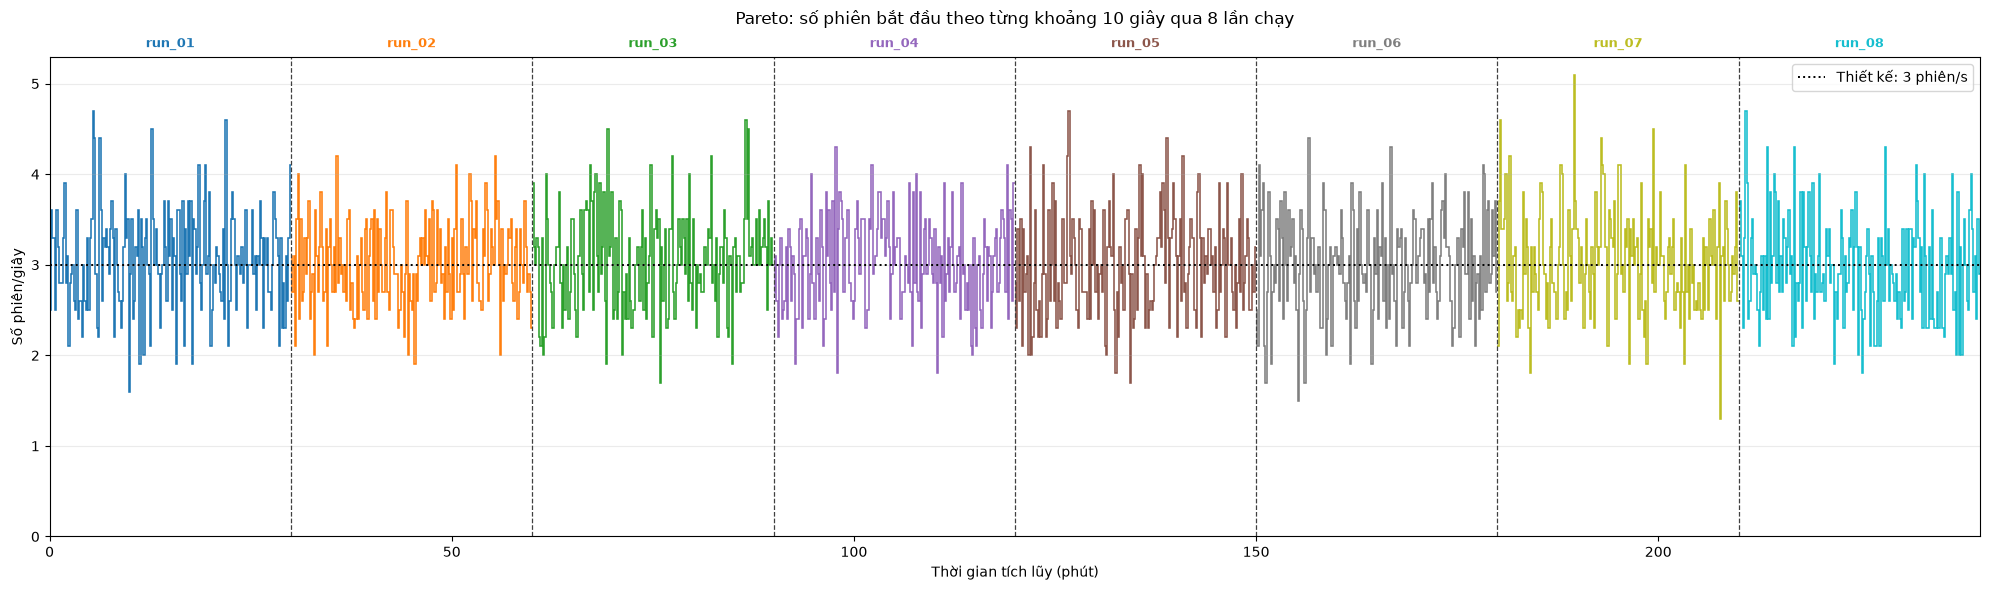

In [4]:
fig, ax = plt.subplots(figsize=(20, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(run_series)))

for idx, (item, color) in enumerate(zip(run_series, colors)):
    ax.stairs(
        item["session_rates"], item["edges_min"],
        baseline=None, color=color, linewidth=1.15,
    )
    midpoint = (item["start_min"] + item["end_min"]) / 2.0
    ax.text(
        midpoint, 1.015, item["run_id"], transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=9, fontweight="bold",
        color=color, clip_on=False,
    )
    if idx > 0:
        ax.axvline(item["start_min"], color="0.25", linestyle="--", linewidth=0.9)

ax.axhline(SESSION_RATE, color="black", linestyle=":", linewidth=1.4, label="Thiết kế: 3 phiên/s")
ax.set_xlim(0, total_minutes)
ax.set_ylim(bottom=0)
ax.set_xlabel("Thời gian tích lũy (phút)")
ax.set_ylabel("Số phiên/giây")
ax.set_title("Pareto: số phiên bắt đầu theo từng khoảng 10 giây qua 8 lần chạy", pad=24)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right")
ax.margins(x=0)
fig.tight_layout()
plt.show()

## RPS tương đương từ trace

Trong mỗi bin, mỗi phiên được gán trọng số $S+3$. Đây là khối lượng request quy về thời điểm phiên bắt đầu, không phải thời điểm gửi request thực tế sau think-time. Đường ngang là $E[\mathrm{RPS}]=3\left(E[S]+3\right)\approx20.284$.

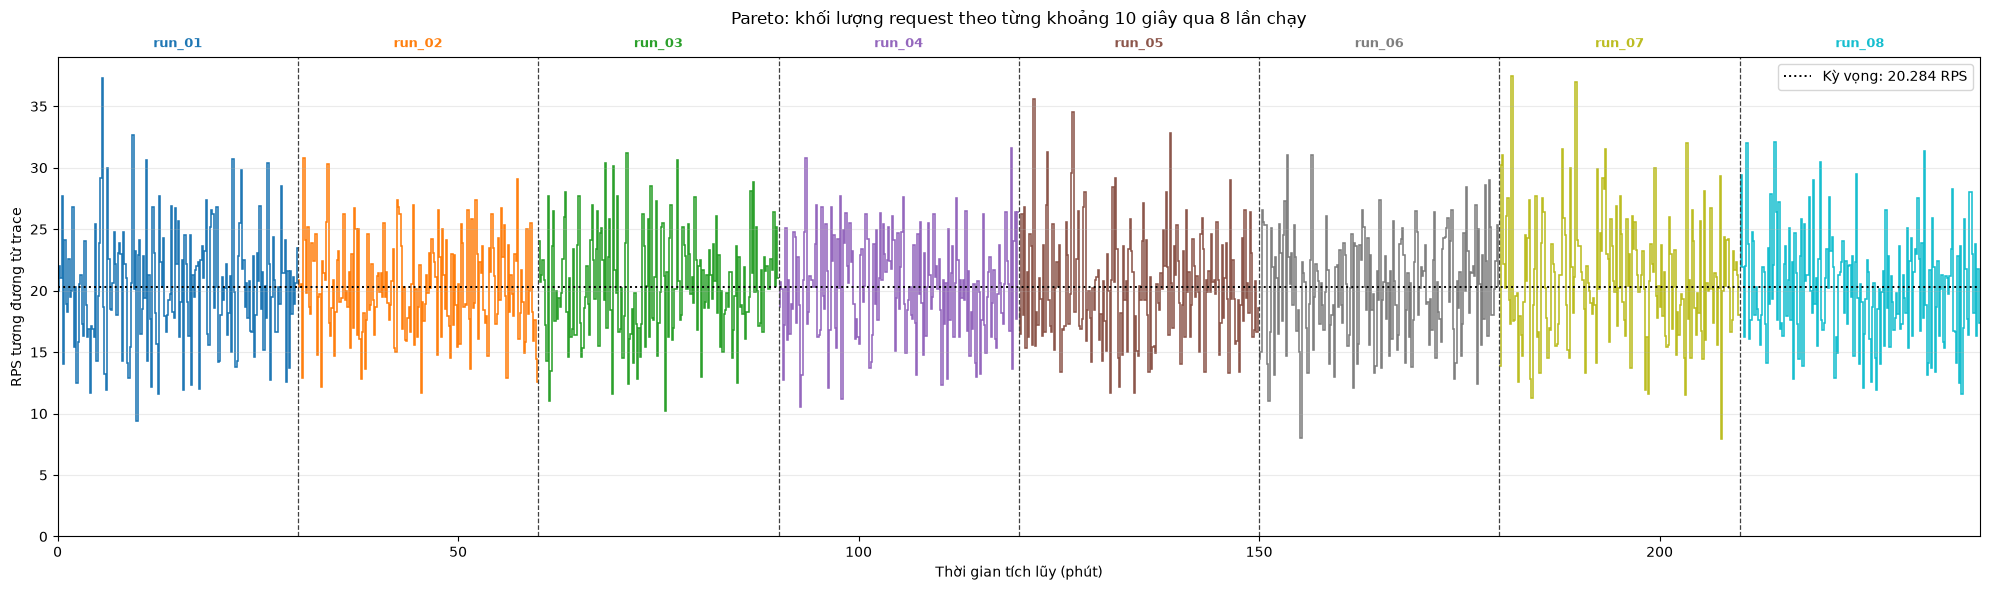

In [5]:
fig, ax = plt.subplots(figsize=(20, 6))

for idx, (item, color) in enumerate(zip(run_series, colors)):
    ax.stairs(
        item["trace_rps"], item["edges_min"],
        baseline=None, color=color, linewidth=1.15,
    )
    midpoint = (item["start_min"] + item["end_min"]) / 2.0
    ax.text(
        midpoint, 1.015, item["run_id"], transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=9, fontweight="bold",
        color=color, clip_on=False,
    )
    if idx > 0:
        ax.axvline(item["start_min"], color="0.25", linestyle="--", linewidth=0.9)

ax.axhline(EXPECTED_RPS, color="black", linestyle=":", linewidth=1.4, label=f"Kỳ vọng: {EXPECTED_RPS:.3f} RPS")
ax.set_xlim(0, total_minutes)
ax.set_ylim(bottom=0)
ax.set_xlabel("Thời gian tích lũy (phút)")
ax.set_ylabel("RPS tương đương từ trace")
ax.set_title("Pareto: khối lượng request theo từng khoảng 10 giây qua 8 lần chạy", pad=24)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right")
ax.margins(x=0)
fig.tight_layout()
plt.show()

## Phân phối số sản phẩm mỗi phiên

Với $S=\lceil X\rceil$, xác suất lý thuyết là $P(S=k)=F_X(k)-F_X(k-1)$. Trục tung logarit giúp quan sát phần đuôi đến 40 sản phẩm.

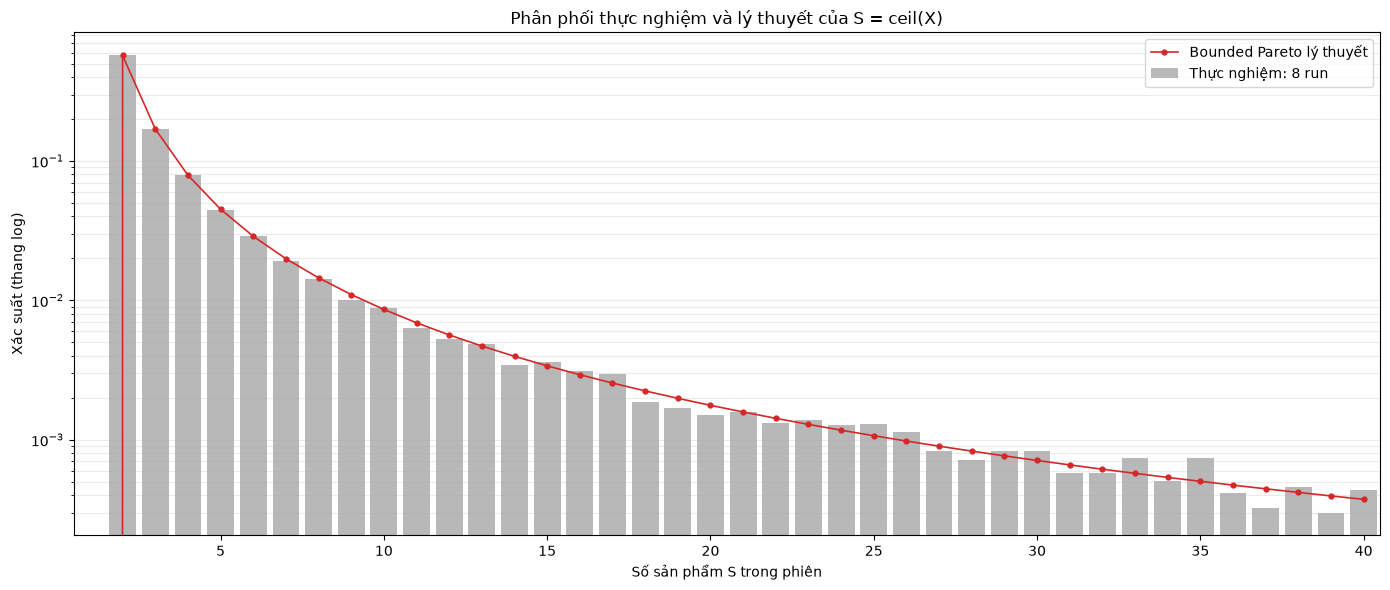

,Chỉ tiêu,Lý thuyết,Thực nghiệm
0,E[S],3.761484,3.750081
1,P(S > 10),0.051760,0.050966
2,P(S ≥ 20),0.017462,0.017749


In [6]:
support = np.arange(1, int(HIGH) + 1)
empirical_counts = np.bincount(all_sizes, minlength=int(HIGH) + 1)[1:]
empirical_pmf = empirical_counts / empirical_counts.sum()
theoretical_pmf = bounded_pareto_cdf(support) - bounded_pareto_cdf(support - 1)

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(support, empirical_pmf, width=0.82, color="0.72", label="Thực nghiệm: 8 run")
ax.plot(support, theoretical_pmf, "o-", color="tab:red", markersize=3.5, linewidth=1.2, label="Bounded Pareto lý thuyết")
ax.set_yscale("log")
ax.set_xlim(0.5, HIGH + 0.5)
ax.set_xlabel("Số sản phẩm S trong phiên")
ax.set_ylabel("Xác suất (thang log)")
ax.set_title("Phân phối thực nghiệm và lý thuyết của S = ceil(X)")
ax.grid(axis="y", which="both", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

tail_summary = pd.DataFrame({
    "Chỉ tiêu": ["E[S]", "P(S > 10)", "P(S ≥ 20)"],
    "Lý thuyết": [EXPECTED_ITEMS, 1 - bounded_pareto_cdf(10), 1 - bounded_pareto_cdf(19)],
    "Thực nghiệm": [all_sizes.mean(), np.mean(all_sizes > 10), np.mean(all_sizes >= 20)],
})
display(tail_summary.style.format({"Lý thuyết": "{:.6f}", "Thực nghiệm": "{:.6f}"}))

## Thống kê theo từng lần chạy

In [7]:
display(
    summary.style.format({
        "Thời lượng (phút)": "{:.2f}",
        "Tổng số phiên": "{:,.0f}",
        "Phiên/giây trung bình": "{:.3f}",
        "S trung bình": "{:.3f}",
        "S cực đại": "{:,.0f}",
        "Phiên S ≥ 20": "{:,.0f}",
        "RPS trace": "{:.3f}",
        "RPS Locust": "{:.3f}",
    })
)

,Run,Thời lượng (phút),Tổng số phiên,Phiên/giây trung bình,S trung bình,S cực đại,Phiên S ≥ 20,RPS trace,RPS Locust
0,run_01,30.00,"5,472",3.040,3.658,40,91,20.239,20.164
1,run_02,30.00,"5,416",3.009,3.700,40,91,20.161,20.111
2,run_03,30.00,"5,475",3.042,3.709,40,96,20.407,20.322
3,run_04,30.00,"5,427",3.015,3.750,40,97,20.350,20.276
4,run_05,30.00,"5,387",2.993,3.755,40,91,20.216,20.163
5,run_06,30.00,"5,391",2.995,3.772,40,91,20.282,20.202
6,run_07,30.00,"5,473",3.041,3.836,40,113,20.787,20.719
7,run_08,30.00,"5,341",2.967,3.822,40,100,20.243,20.196
